# V18: missing-order teacher — early stop

**FINAL CPU result. No feature generation, head training, GPU or submission.**
The fixed teacher preserves H60 on its route and averages all four expert/order
predictions off-route. On the fixed 512 rows it slightly worsens loss, failing
the predeclared strict >0.001 improvement gate. We retain official 0.82987.

Original votes overlap checkpoint training; the intervals below describe these
samples and are neither competition CV nor a score forecast. The interval
includes zero, so the result does not establish harm. No alternate teacher was
tried. See [contract](../docs/SPAN_018_PLAN.md) and
[report](../docs/SPAN_018_RESULTS.md). The rank ≤19 goal remains active.

,cohort,rows,unchanged_on_route_rows,teacher_off_route_rows,parent_log_loss,teacher_log_loss,loss_reduction,descriptive_paired_group95,parent_accuracy,teacher_accuracy
0,control,256,42,214,0.598234,0.598817,-0.000583,"[-0.004005, 0.002925]",0.773438,0.781250
1,uniform,512,83,429,0.652988,0.653247,-0.000259,"[-0.002663, 0.002169]",0.751953,0.748047
2,long,64,6,58,0.896484,0.899929,-0.003445,"[-0.016015, 0.008354]",0.609375,0.609375


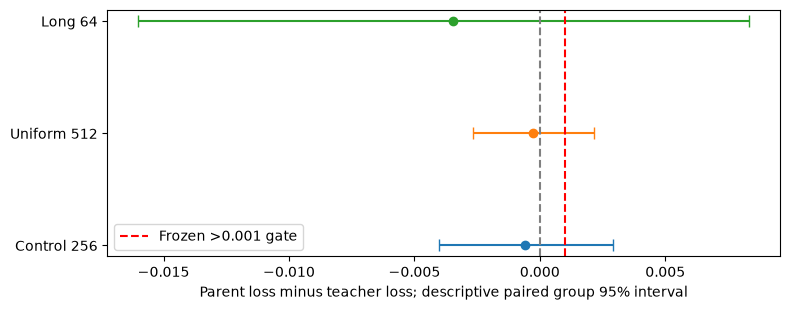

Teacher variants: 1 ; new parameter fits: 0
GPU executions: 0 ; official eligible: False
Decision: stop before feature inference; retain H60. No independent teacher advantage measured.


In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
REPO = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
r = json.loads((REPO/'results/span_018/H64_teacher_replay.json').read_text())
records = r['coverage']
display(pd.DataFrame([{'cohort':name, **{k:v for k,v in row.items()
 if k in ['rows','unchanged_on_route_rows','teacher_off_route_rows',
 'parent_log_loss','teacher_log_loss','loss_reduction','descriptive_paired_group95',
 'parent_accuracy','teacher_accuracy']}}
 for name,row in records.items() if name != 'test']))
fig, ax = plt.subplots(figsize=(8,3.2))
for i, name in enumerate(['control','uniform','long']):
 row=records[name];gain=row['loss_reduction'];lo,hi=row['descriptive_paired_group95']
 ax.errorbar(gain,i,xerr=[[gain-lo],[hi-gain]],fmt='o',capsize=4)
ax.axvline(0,color='gray',linestyle='--')
ax.axvline(r['minimum_useful_teacher_gain'],color='red',linestyle='--',label='Frozen >0.001 gate')
ax.set_yticks(range(3),['Control 256','Uniform 512','Long 64'])
ax.set_xlabel('Parent loss minus teacher loss; descriptive paired group 95% interval')
ax.legend();fig.tight_layout();plt.show()
assert not r['information_gate_passed']
assert all(row['on_route_byte_values_unchanged'] for row in records.values())
print('Teacher variants:',r['teacher_variants_tested'],'; new parameter fits:',r['new_parameter_fits'])
print('GPU executions:',r['new_gpu_executions'],'; official eligible:',r['official_submission_eligible'])
print('Decision: stop before feature inference; retain H60. No independent teacher advantage measured.')

In [2]:
inventory=json.loads((REPO/'results/span_018/terminal_inventory.json').read_text())
board=json.loads((REPO/'results/span_018/final_leaderboard.json').read_text())
history=json.loads((REPO/'results/span_018/terminal_official_history.json').read_text())
assert not inventory['nonterminal_jobs'] and history['complete'] and board['complete']
print('Inventory observed at:',inventory['observed_at'])
print('Owned notebooks:',inventory['owned_notebook_count'],'; active:',len(inventory['nonterminal_jobs']))
print('Free GPU hours:',inventory['quota']['remaining_seconds']/3600)
print('Official position:',board['rank'],'of',board['teams'],'; loss:',board['score'])
print('Rank 19 cutoff:',board['rank19_score'],'; rank goal achieved:',board['target_achieved'])
print('Official receipts:',len(history['receipts']),'; no new submission in this span.')

Inventory observed at: 2026-11-08T08:28:32.573512+00:00
Owned notebooks: 66 ; active: 0
Free GPU hours: 25.448171388888888
Official position: 23 of 310 ; loss: 0.82987
Rank 19 cutoff: 0.82915 ; rank goal achieved: False
Official receipts: 7 ; no new submission in this span.
